# Heart Failure Prediction

## 1. Setup

In [1]:
import pandas as pd
import numpy as np

import seaborn as sns
from matplotlib import pyplot as plt
%matplotlib inline

## 2. Load the data

In [2]:
df = pd.read_csv('data/heart.csv')
df.shape

(918, 12)

In [3]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [4]:
df.dtypes

Age                 int64
Sex                   str
ChestPainType         str
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG            str
MaxHR               int64
ExerciseAngina        str
Oldpeak           float64
ST_Slope              str
HeartDisease        int64
dtype: object

## 3. Data preparation

In [5]:
df = df.rename(columns={
    'Age': 'age',
    'Sex': 'sex',
    'ChestPainType': 'chest_pain_type',
    'RestingBP': 'resting_bp',
    'Cholesterol': 'cholesterol',
    'FastingBS': 'fasting_bs',
    'RestingECG': 'resting_ecg',
    'MaxHR': 'max_hr',
    'ExerciseAngina': 'exercise_angina',
    'Oldpeak': 'oldpeak',
    'ST_Slope': 'st_slope',
    'HeartDisease': 'heart_disease',
})

df.columns

Index(['age', 'sex', 'chest_pain_type', 'resting_bp', 'cholesterol',
       'fasting_bs', 'resting_ecg', 'max_hr', 'exercise_angina', 'oldpeak',
       'st_slope', 'heart_disease'],
      dtype='str')

In [6]:
categorical = ['sex', 'chest_pain_type', 'resting_ecg', 'exercise_angina', 'st_slope']
numerical = ['age', 'resting_bp', 'cholesterol', 'fasting_bs', 'max_hr', 'oldpeak']

for c in categorical:
    df[c] = df[c].str.lower()

df.head()

,age,sex,chest_pain_type,resting_bp,cholesterol,fasting_bs,resting_ecg,max_hr,exercise_angina,oldpeak,st_slope,heart_disease
0,40,m,ata,140,289,0,normal,172,n,0.0,up,0
1,49,f,nap,160,180,0,normal,156,n,1.0,flat,1
2,37,m,ata,130,283,0,st,98,n,0.0,up,0
3,48,f,asy,138,214,0,normal,108,y,1.5,flat,1
4,54,m,nap,150,195,0,normal,122,n,0.0,up,0


## 4. Exploratory data analysis

In [7]:
df.isnull().sum()

age                0
sex                0
chest_pain_type    0
resting_bp         0
cholesterol        0
fasting_bs         0
resting_ecg        0
max_hr             0
exercise_angina    0
oldpeak            0
st_slope           0
heart_disease      0
dtype: int64

In [8]:
df[numerical].describe().round(2)

,age,resting_bp,cholesterol,fasting_bs,max_hr,oldpeak
count,918.00,918.00,918.00,918.00,918.00,918.00
mean,53.51,132.40,198.80,0.23,136.81,0.89
std,9.43,18.51,109.38,0.42,25.46,1.07
min,28.00,0.00,0.00,0.00,60.00,-2.60
25%,47.00,120.00,173.25,0.00,120.00,0.00
50%,54.00,130.00,223.00,0.00,138.00,0.60
75%,60.00,140.00,267.00,0.00,156.00,1.50
max,77.00,200.00,603.00,1.00,202.00,6.20


In [9]:
(df[numerical] == 0).sum()

age              0
resting_bp       1
cholesterol    172
fasting_bs     704
max_hr           0
oldpeak        368
dtype: int64

In [10]:
df[df.resting_bp == 0].T

,449
age,55
sex,m
chest_pain_type,nap
resting_bp,0
cholesterol,0
fasting_bs,0
resting_ecg,normal
max_hr,155
exercise_angina,n
oldpeak,1.5


### 4.3 Where do the cholesterol zeros come from?

Is a missing cholesterol value related to heart disease?

In [11]:
df.groupby(df.cholesterol == 0).heart_disease.agg(['count', 'mean'])

,count,mean
cholesterol,,
False,746,0.477212
True,172,0.883721


### 4.4 Mark the zeros as missing

We replace the zeros in `cholesterol` and `resting_bp` with `NaN` (missing).

At this point, they're not filled in yet. After the data split, missing values will be filled with median value calculated from training data.

In [12]:
df['cholesterol'] = df['cholesterol'].replace(0, np.nan)
df['resting_bp'] = df['resting_bp'].replace(0, np.nan)

df.isnull().sum()

age                  0
sex                  0
chest_pain_type      0
resting_bp           1
cholesterol        172
fasting_bs           0
resting_ecg          0
max_hr               0
exercise_angina      0
oldpeak              0
st_slope             0
heart_disease        0
dtype: int64

In [13]:
df[numerical].describe().round(2)

,age,resting_bp,cholesterol,fasting_bs,max_hr,oldpeak
count,918.00,917.00,746.00,918.00,918.00,918.00
mean,53.51,132.54,244.64,0.23,136.81,0.89
std,9.43,18.00,59.15,0.42,25.46,1.07
min,28.00,80.00,85.00,0.00,60.00,-2.60
25%,47.00,120.00,207.25,0.00,120.00,0.00
50%,54.00,130.00,237.00,0.00,138.00,0.60
75%,60.00,140.00,275.00,0.00,156.00,1.50
max,77.00,200.00,603.00,1.00,202.00,6.20


### 4.5 Target variable

In [14]:
df.heart_disease.value_counts()

heart_disease
1    508
0    410
Name: count, dtype: int64

In [15]:
df.heart_disease.value_counts(normalize=True).round(3)

heart_disease
1    0.553
0    0.447
Name: proportion, dtype: float64

In [16]:
global_rate = df.heart_disease.mean()
round(global_rate, 3)

np.float64(0.553)

### 4.6 Numerical features

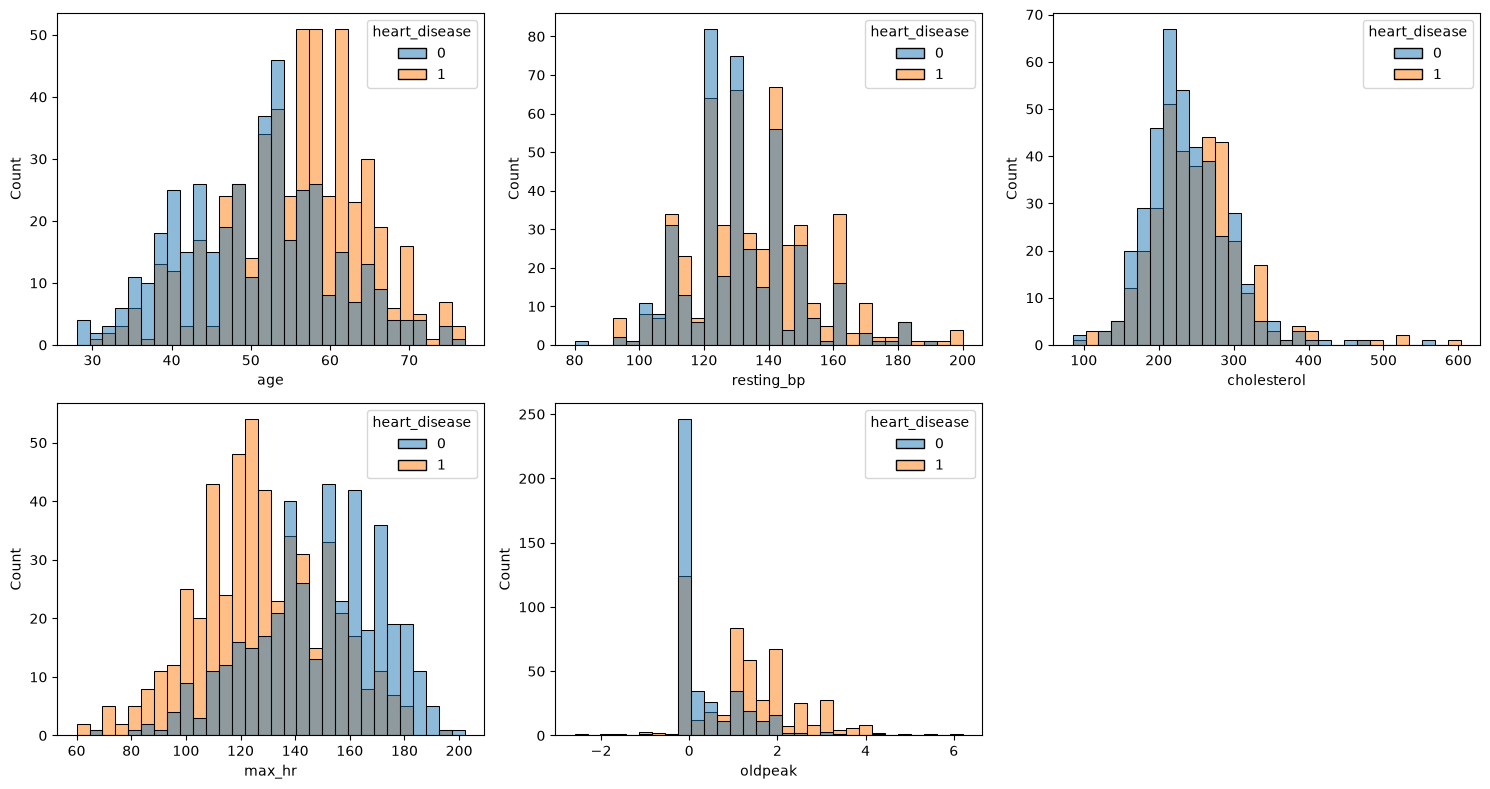

In [17]:
continuous = ['age', 'resting_bp', 'cholesterol', 'max_hr', 'oldpeak']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.flat, continuous):
    sns.histplot(data=df, x=col, hue='heart_disease', bins=30, ax=ax)

axes.flat[-1].set_visible(False)
plt.tight_layout()

In [18]:
df.groupby('heart_disease')[continuous].mean().round(1)

,age,resting_bp,cholesterol,max_hr,oldpeak
heart_disease,,,,,
0,50.6,130.2,238.8,148.2,0.4
1,55.9,134.4,251.1,127.7,1.3


### 4.7 Categorical features

In [19]:
for c in categorical + ['fasting_bs']:
    print(df[c].value_counts())
    print()

sex
m    725
f    193
Name: count, dtype: int64

chest_pain_type
asy    496
nap    203
ata    173
ta      46
Name: count, dtype: int64

resting_ecg
normal    552
lvh       188
st        178
Name: count, dtype: int64

exercise_angina
n    547
y    371
Name: count, dtype: int64

st_slope
flat    460
up      395
down     63
Name: count, dtype: int64

fasting_bs
0    704
1    214
Name: count, dtype: int64



## 5. Validation framework

In [20]:
from sklearn.model_selection import train_test_split

# 60% train, 20% validation, 20% test
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

len(df_train), len(df_val), len(df_test)

(550, 184, 184)

In [21]:
df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [22]:
y_train = df_train.heart_disease.values
y_val = df_val.heart_disease.values
y_test = df_test.heart_disease.values

del df_train['heart_disease']
del df_val['heart_disease']
del df_test['heart_disease']

## 6. Feature importance

Calculated on `df_full_train` only, so the test set stays unseen.

### 6.1 Risk ratio (categorical features)

In [23]:
global_rate = df_full_train.heart_disease.mean()
round(global_rate, 3)

np.float64(0.542)

In [24]:
from IPython.display import display

# risk > 1: more likely than average to have heart disease; risk < 1: less likely
for c in categorical + ['fasting_bs']:
    df_group = df_full_train.groupby(c).heart_disease.agg(['mean', 'count'])
    df_group['diff'] = df_group['mean'] - global_rate
    df_group['risk'] = df_group['mean'] / global_rate
    print(c)
    display(df_group.round(3))
    print()

sex


,mean,count,diff,risk
sex,,,,
f,0.255,157,-0.287,0.470
m,0.620,577,0.078,1.144



chest_pain_type


,mean,count,diff,risk
chest_pain_type,,,,
asy,0.774,394,0.232,1.428
ata,0.120,133,-0.422,0.222
nap,0.345,168,-0.197,0.637
ta,0.487,39,-0.055,0.898



resting_ecg


,mean,count,diff,risk
resting_ecg,,,,
lvh,0.520,152,-0.022,0.959
normal,0.511,436,-0.031,0.943
st,0.658,146,0.115,1.213


... (2 outputs left out)


st_slope


,mean,count,diff,risk
st_slope,,,,
down,0.718,39,0.176,1.324
flat,0.810,373,0.267,1.493
up,0.211,322,-0.331,0.389



fasting_bs


,mean,count,diff,risk
fasting_bs,,,,
0,0.476,565,-0.066,0.878
1,0.763,169,0.221,1.408


### 6.2 Mutual information (categorical features)

In [25]:
from sklearn.metrics import mutual_info_score

def mutual_info_heart_disease_score(series):
    return mutual_info_score(series, df_full_train.heart_disease)

mi = df_full_train[categorical + ['fasting_bs']].apply(mutual_info_heart_disease_score)
mi.sort_values(ascending=False).round(3)

st_slope           0.184
chest_pain_type    0.152
exercise_angina    0.123
sex                0.046
fasting_bs         0.031
resting_ecg        0.007
dtype: float64

### 6.3 Correlation (numerical features)

In [26]:
# positive: higher value -> more heart disease; negative: higher value -> less
df_full_train[numerical].corrwith(df_full_train.heart_disease).sort_values().round(3)

max_hr        -0.396
cholesterol    0.080
resting_bp     0.120
fasting_bs     0.243
age            0.277
oldpeak        0.378
dtype: float64

In [27]:
df_full_train[numerical].corrwith(df_full_train.heart_disease).abs().sort_values(ascending=False).round(3)

max_hr         0.396
oldpeak        0.378
age            0.277
fasting_bs     0.243
resting_bp     0.120
cholesterol    0.080
dtype: float64

### 6.4 Missing cholesterol as a signal

In [28]:
# 1 = cholesterol was missing (recorded as 0), 0 = measured
cholesterol_missing = df_full_train.cholesterol.isnull().astype(int)

round(cholesterol_missing.corr(df_full_train.heart_disease), 3)

np.float64(0.353)

## 7. Filling in the missing values

We compare three ways to fill the missing values, using logistic regression and the validation set.

In [29]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

features = categorical + numerical

def prepare_dicts(df, fill_values, add_flag=False):
    df = df[features].copy()

    if add_flag:
        # 1 = cholesterol was missing, 0 = measured
        df['cholesterol_missing'] = df.cholesterol.isnull().astype(int)

    df = df.fillna(fill_values)
    return df.to_dict(orient='records')

In [30]:
# fill values calculated from the training data only
fill_zero = {'cholesterol': 0, 'resting_bp': 0}

fill_median = {
    'cholesterol': df_train.cholesterol.median(),
    'resting_bp': df_train.resting_bp.median(),
}
fill_median

{'cholesterol': np.float64(236.0), 'resting_bp': np.float64(130.0)}

In [31]:
def evaluate_fill(fill_values, add_flag=False):
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(prepare_dicts(df_train, fill_values, add_flag))
    X_val = dv.transform(prepare_dicts(df_val, fill_values, add_flag))

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_train, y_train)

    y_pred = model.predict_proba(X_val)[:, 1]
    return roc_auc_score(y_val, y_pred)


options = [
    ('zeros', fill_zero, False),
    ('median', fill_median, False),
    ('median + missing flag', fill_median, True),
]

for name, fill_values, add_flag in options:
    auc = evaluate_fill(fill_values, add_flag)
    print('%-22s %.3f' % (name, auc))

zeros                  0.909
median                 0.903
median + missing flag  0.909


**Decision:** fill with the training median. See README for details.

## 8. Logistic regression

### 8.1 Baseline to beat

In [32]:
# dummy model: say "heart disease" for every patient
y_dummy = np.ones(len(y_val))

accuracy = (y_dummy == y_val).mean()
auc = roc_auc_score(y_val, y_dummy)

round(accuracy, 3), auc

(np.float64(0.533), 0.5)

### 8.2 Logistic regression on the validation set

In [33]:
dv = DictVectorizer(sparse=False)

train_dicts = prepare_dicts(df_train, fill_median)
val_dicts = prepare_dicts(df_val, fill_median)

X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:, 1]
round(roc_auc_score(y_val, y_pred), 3)

0.903

In [34]:
t = 0.5

actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

predict_positive = (y_pred >= t)
predict_negative = (y_pred < t)

tp = (predict_positive & actual_positive).sum()
tn = (predict_negative & actual_negative).sum()
fp = (predict_positive & actual_negative).sum()
fn = (predict_negative & actual_positive).sum()

confusion_matrix = np.array([
    [tn, fp],
    [fn, tp]
])
confusion_matrix

array([[70, 16],
       [16, 82]])

In [35]:
accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp)
recall = tp / (tp + fn)

round(accuracy, 3), round(precision, 3), round(recall, 3)

(np.float64(0.826), np.float64(0.837), np.float64(0.837))

### 8.3 Tuning `C` with 5-fold cross-validation

In [37]:
from sklearn.model_selection import KFold

def train(df_train, y_train, C=1.0):
    # fill values come from this training data only
    fill_values = {
        'cholesterol': df_train.cholesterol.median(),
        'resting_bp': df_train.resting_bp.median(),
    }
    dicts = prepare_dicts(df_train, fill_values)

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)

    return fill_values, dv, model


def predict(df, fill_values, dv, model):
    dicts = prepare_dicts(df, fill_values)
    X = dv.transform(dicts)
    return model.predict_proba(X)[:, 1]

In [38]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

for C in [0.001, 0.01, 0.1, 0.5, 1, 5, 10]:
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_fold_train = df_full_train.iloc[train_idx]
        df_fold_val = df_full_train.iloc[val_idx]

        y_fold_train = df_fold_train.heart_disease.values
        y_fold_val = df_fold_val.heart_disease.values

        fill_values, dv, model = train(df_fold_train, y_fold_train, C=C)
        y_pred = predict(df_fold_val, fill_values, dv, model)

        scores.append(roc_auc_score(y_fold_val, y_pred))

    print('C=%-6s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

C=0.001  0.787 +- 0.046
C=0.01   0.886 +- 0.040
C=0.1    0.913 +- 0.030
C=0.5    0.914 +- 0.028
C=1      0.913 +- 0.027
C=5      0.913 +- 0.026
C=10     0.913 +- 0.026


`C` from 0.1 to 10 gives practically the same AUC, so we keep `C=1.0`.

## 9. Decision tree

In [39]:
from sklearn.tree import DecisionTreeClassifier

# same features as logistic regression: missing values filled with the training median
dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(prepare_dicts(df_train, fill_median))
X_val = dv.transform(prepare_dicts(df_val, fill_median))

In [40]:
for depth in [1, 2, 3, 4, 5, 6, 10, 15, 20, None]:
    dt = DecisionTreeClassifier(max_depth=depth, random_state=1)
    dt.fit(X_train, y_train)

    y_pred = dt.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)

    print('%4s -> %.3f' % (depth, auc))

   1 -> 0.742
   2 -> 0.822
   3 -> 0.854
   4 -> 0.846
   5 -> 0.824
   6 -> 0.807
  10 -> 0.719
  15 -> 0.736
  20 -> 0.736
None -> 0.736


In [41]:
scores = []

for depth in [3, 4, 5, 6]:
    for s in [1, 5, 10, 15, 20, 50, 100]:
        dt = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=s, random_state=1)
        dt.fit(X_train, y_train)

        y_pred = dt.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((depth, s, auc))

df_scores = pd.DataFrame(scores, columns=['max_depth', 'min_samples_leaf', 'auc'])
df_scores.sort_values(by='auc', ascending=False).head()

,max_depth,min_samples_leaf,auc
11,4,20,0.871322
18,5,20,0.868237
25,6,20,0.867940
17,5,15,0.864143
24,6,15,0.863313


<Axes: xlabel='max_depth', ylabel='min_samples_leaf'>

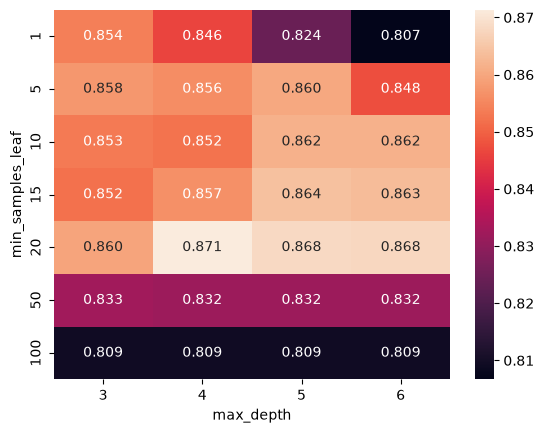

In [42]:
df_scores_pivot = df_scores.pivot(index='min_samples_leaf', columns='max_depth', values='auc')
sns.heatmap(df_scores_pivot, annot=True, fmt='.3f')

Best: `max_depth=4`, `min_samples_leaf=20`.

## 10. Random forest

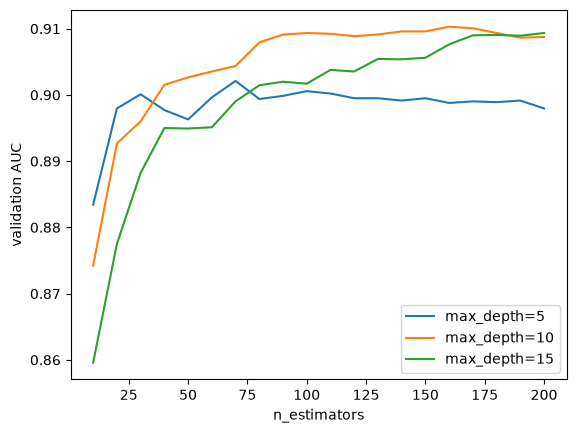

In [43]:
from sklearn.ensemble import RandomForestClassifier

scores = []

for d in [5, 10, 15]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators=n, max_depth=d, random_state=1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((d, n, auc))

df_scores = pd.DataFrame(scores, columns=['max_depth', 'n_estimators', 'auc'])

for d in [5, 10, 15]:
    df_subset = df_scores[df_scores.max_depth == d]
    plt.plot(df_subset.n_estimators, df_subset.auc, label='max_depth=%d' % d)

plt.xlabel('n_estimators')
plt.ylabel('validation AUC')
plt.legend()

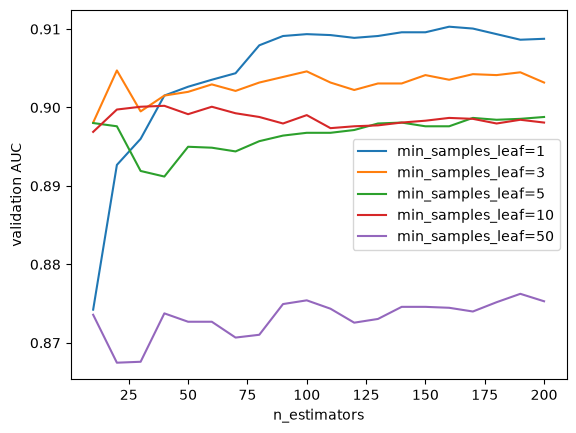

In [44]:
max_depth = 10

scores = []

for s in [1, 3, 5, 10, 50]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators=n, max_depth=max_depth, min_samples_leaf=s, random_state=1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((s, n, auc))

df_scores = pd.DataFrame(scores, columns=['min_samples_leaf', 'n_estimators', 'auc'])

for s in [1, 3, 5, 10, 50]:
    df_subset = df_scores[df_scores.min_samples_leaf == s]
    plt.plot(df_subset.n_estimators, df_subset.auc, label='min_samples_leaf=%d' % s)

plt.xlabel('n_estimators')
plt.ylabel('validation AUC')
plt.legend()

In [45]:
df_scores.sort_values(by='auc', ascending=False).head()

,min_samples_leaf,n_estimators,auc
15,1,160,0.910299
16,1,170,0.910062
13,1,140,0.909587
14,1,150,0.909587
17,1,180,0.909350


Best: `max_depth=10`, `min_samples_leaf=1`, `n_estimators=160`.

## 11. XGBoost

In [46]:
import xgboost as xgb

feature_names = list(dv.get_feature_names_out())

dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=feature_names)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=feature_names)

watchlist = [(dtrain, 'train'), (dval, 'val')]

In [47]:
def train_xgb(eta=0.3, max_depth=6, min_child_weight=1, num_boost_round=200):
    xgb_params = {
        'eta': eta,
        'max_depth': max_depth,
        'min_child_weight': min_child_weight,

        'objective': 'binary:logistic',
        'eval_metric': 'auc',

        'nthread': 8,
        'seed': 1,
        'verbosity': 1,
    }

    # evals_result collects the train/val AUC after every round
    # (the same numbers the lecture parsed from the printed output)
    evals_result = {}
    xgb.train(xgb_params, dtrain, num_boost_round=num_boost_round,
              evals=watchlist, evals_result=evals_result, verbose_eval=False)

    return pd.DataFrame({
        'num_iter': range(1, num_boost_round + 1),
        'train_auc': evals_result['train']['auc'],
        'val_auc': evals_result['val']['auc'],
    })


def show_scores(scores):
    for key, df_score in scores.items():
        plt.plot(df_score.num_iter, df_score.val_auc, label=key)

        best = df_score.loc[df_score.val_auc.idxmax()]
        print('%-20s best val AUC %.3f after %d rounds' % (key, best.val_auc, best.num_iter))

    plt.xlabel('num_boost_round')
    plt.ylabel('validation AUC')
    plt.legend()

### 11.1 Tuning `eta`

eta=0.01             best val AUC 0.875 after 169 rounds
eta=0.05             best val AUC 0.881 after 82 rounds
eta=0.1              best val AUC 0.882 after 164 rounds
eta=0.3              best val AUC 0.891 after 15 rounds
eta=1.0              best val AUC 0.883 after 4 rounds


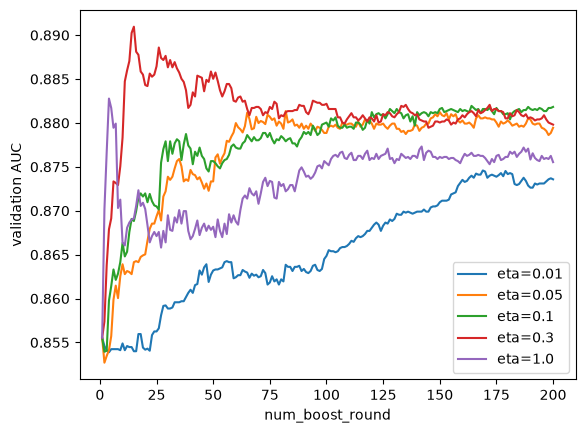

In [48]:
scores = {}

for eta in [0.01, 0.05, 0.1, 0.3, 1.0]:
    scores['eta=%s' % eta] = train_xgb(eta=eta)

show_scores(scores)

`eta=0.3` and `1.0` peak early and then get worse, so we would have to stop at exactly the right round.

`0.05` (0.881) and `0.1` (0.882) are tied. A smaller `eta` just needs more rounds. We take `eta=0.05` because its curve stays flat near the peak, so 200 rounds is a safe choice.

### 11.2 Tuning `max_depth`

max_depth=2          best val AUC 0.908 after 190 rounds
max_depth=3          best val AUC 0.894 after 105 rounds
max_depth=4          best val AUC 0.892 after 92 rounds
max_depth=6          best val AUC 0.881 after 82 rounds
max_depth=10         best val AUC 0.879 after 125 rounds


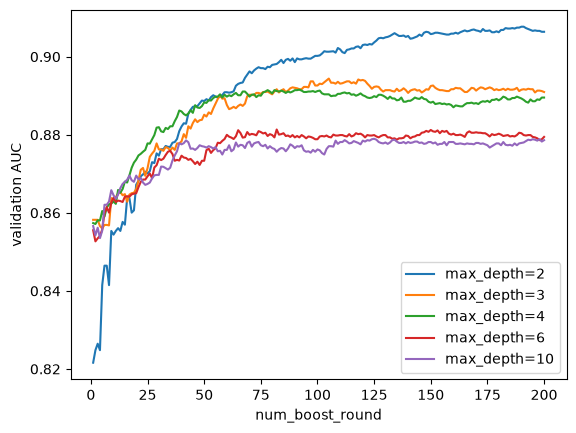

In [49]:
scores = {}

for depth in [2, 3, 4, 6, 10]:
    scores['max_depth=%s' % depth] = train_xgb(eta=0.05, max_depth=depth)

show_scores(scores)

Shallow trees work best on this small dataset. We use `max_depth=2`.

### 11.3 Tuning `min_child_weight`

min_child_weight=1   best val AUC 0.908 after 190 rounds
min_child_weight=5   best val AUC 0.906 after 191 rounds
min_child_weight=10  best val AUC 0.904 after 167 rounds
min_child_weight=20  best val AUC 0.873 after 196 rounds


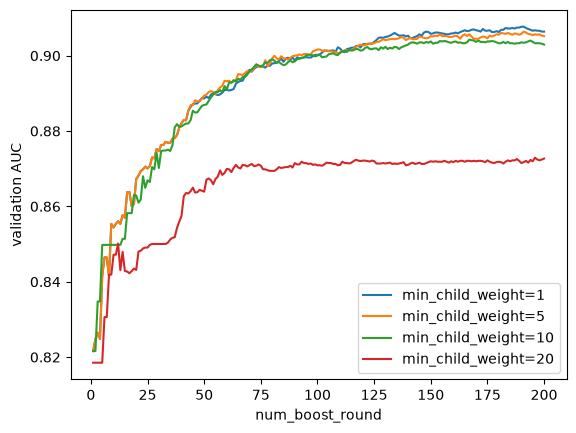

In [50]:
scores = {}

for m in [1, 5, 10, 20]:
    scores['min_child_weight=%s' % m] = train_xgb(eta=0.05, max_depth=2, min_child_weight=m)

show_scores(scores)

Best: `eta=0.05`, `max_depth=2`, `min_child_weight=1`, 200 rounds.

## 12. Choosing the final model

In [51]:
xgb_params_final = {
    'eta': 0.05,
    'max_depth': 2,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

# the best version of each model
models = {
    'logistic_regression': lambda: LogisticRegression(solver='liblinear', C=1.0, max_iter=1000),
    'decision_tree': lambda: DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, random_state=1),
    'random_forest': lambda: RandomForestClassifier(n_estimators=160, max_depth=10, random_state=1),
    'xgboost': None,  # trained with xgb.train in fit_predict, using xgb_params_final
}


def fit_predict(name, X_train, y_train, X_val, feature_names):
    if name == 'xgboost':
        dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=feature_names)
        dval = xgb.DMatrix(X_val, feature_names=feature_names)
        model = xgb.train(xgb_params_final, dtrain, num_boost_round=200)
        return model.predict(dval)

    model = models[name]()
    model.fit(X_train, y_train)
    return model.predict_proba(X_val)[:, 1]

### 12.1 On the validation set

In [52]:
for name in models:
    y_pred = fit_predict(name, X_train, y_train, X_val, feature_names)
    print('%-20s %.3f' % (name, roc_auc_score(y_val, y_pred)))

logistic_regression  0.903
decision_tree        0.871
random_forest        0.910
xgboost              0.906


### 12.2 With 5-fold cross-validation

The validation set has only 184 patients, so we also compare the models with 5-fold cross-validation on the full training data.

In [53]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

for name in models:
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_fold_train = df_full_train.iloc[train_idx]
        df_fold_val = df_full_train.iloc[val_idx]

        y_fold_train = df_fold_train.heart_disease.values
        y_fold_val = df_fold_val.heart_disease.values

        # fill values from this fold's training part only
        fill_values = {
            'cholesterol': df_fold_train.cholesterol.median(),
            'resting_bp': df_fold_train.resting_bp.median(),
        }

        dv_fold = DictVectorizer(sparse=False)
        X_fold_train = dv_fold.fit_transform(prepare_dicts(df_fold_train, fill_values))
        X_fold_val = dv_fold.transform(prepare_dicts(df_fold_val, fill_values))

        y_pred = fit_predict(name, X_fold_train, y_fold_train, X_fold_val, list(dv_fold.get_feature_names_out()))
        scores.append(roc_auc_score(y_fold_val, y_pred))

    print('%-20s %.3f +- %.3f' % (name, np.mean(scores), np.std(scores)))

logistic_regression  0.913 +- 0.027
decision_tree        0.895 +- 0.030
random_forest        0.918 +- 0.028
xgboost              0.919 +- 0.022


**Decision:** XGBoost has the highest and most stable cross-validation AUC. Please see README for details.

## 13. Choosing the decision threshold

On the validation set, with XGBoost trained on the training data.

In [54]:
y_pred = fit_predict('xgboost', X_train, y_train, X_val, feature_names)

scores = []

for t in np.linspace(0, 1, 21):
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    scores.append((t, tp, fp, fn, tn))

df_scores = pd.DataFrame(scores, columns=['threshold', 'tp', 'fp', 'fn', 'tn'])
df_scores['threshold'] = df_scores.threshold.round(2)
df_scores['precision'] = df_scores.tp / (df_scores.tp + df_scores.fp)
df_scores['recall'] = df_scores.tp / (df_scores.tp + df_scores.fn)

df_scores[(df_scores.threshold >= 0.2) & (df_scores.threshold <= 0.7)].round(3)

,threshold,tp,fp,fn,tn,precision,recall
4,0.20,93,39,5,47,0.705,0.949
5,0.25,91,34,7,52,0.728,0.929
6,0.30,90,28,8,58,0.763,0.918
7,0.35,88,22,10,64,0.800,0.898
8,0.40,87,21,11,65,0.806,0.888
9,0.45,85,17,13,69,0.833,0.867
10,0.50,83,15,15,71,0.847,0.847
11,0.55,81,13,17,73,0.862,0.827
12,0.60,79,10,19,76,0.888,0.806
13,0.65,76,9,22,77,0.894,0.776


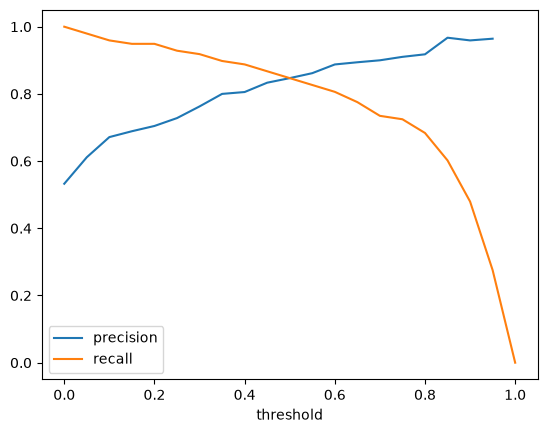

In [55]:
plt.plot(df_scores.threshold, df_scores.precision, label='precision')
plt.plot(df_scores.threshold, df_scores.recall, label='recall')

plt.xlabel('threshold')
plt.legend()

In [56]:
# the highest threshold that still finds at least 90% of the patients with heart disease
threshold = df_scores[df_scores.recall >= 0.9].threshold.max()
threshold

np.float64(0.3)

## 14. Final model on the test set

Trained on the full training data (train + validation), then scored once on the test set.

In [57]:
y_full_train = df_full_train.heart_disease.values

fill_final = {
    'cholesterol': df_full_train.cholesterol.median(),
    'resting_bp': df_full_train.resting_bp.median(),
}

dv = DictVectorizer(sparse=False)
X_full_train = dv.fit_transform(prepare_dicts(df_full_train, fill_final))
X_test = dv.transform(prepare_dicts(df_test, fill_final))

y_pred = fit_predict('xgboost', X_full_train, y_full_train, X_test, list(dv.get_feature_names_out()))

round(roc_auc_score(y_test, y_pred), 3)

0.956

In [58]:
actual_positive = (y_test == 1)
actual_negative = (y_test == 0)

predict_positive = (y_pred >= threshold)
predict_negative = (y_pred < threshold)

tp = (predict_positive & actual_positive).sum()
tn = (predict_negative & actual_negative).sum()
fp = (predict_positive & actual_negative).sum()
fn = (predict_negative & actual_positive).sum()

confusion_matrix = np.array([
    [tn, fp],
    [fn, tp]
])
confusion_matrix

array([[ 60,  14],
       [  4, 106]])

In [59]:
precision = tp / (tp + fp)
recall = tp / (tp + fn)

round(precision, 3), round(recall, 3)

(np.float64(0.883), np.float64(0.964))